# Customer Churn: Exploratory Analysis

**Goal:** find which customers leave, and how much churn costs the company.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/churn_clean.csv")
df.shape

(7043, 20)

In [3]:
overall_churn = df["Churn"].mean()
print(f"Overall Churn: {overall_churn:.1%}")

Overall Churn: 26.5%


In [4]:
df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

In [5]:
def plot_churn_rate(column):
    rate = df.groupby(column)["Churn"].mean().sort_values(ascending=False)*100
    ax = rate.plot(kind="bar", color="steelblue", figsize=(7, 4))
    ax.axhline(overall_churn*100, color="red", linestyle="dashed", label = f"Average({overall_churn:.1%})")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_title(f"Churn rate for {column}")
    ax.legend()
    plt.xticks(rotation=20, ha="right")
    plt.savefig(f"../images/churn_by_{column}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return rate.round(1)

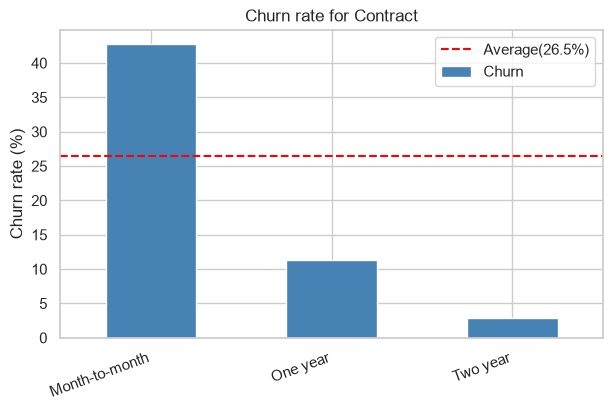

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

In [6]:
plot_churn_rate("Contract")

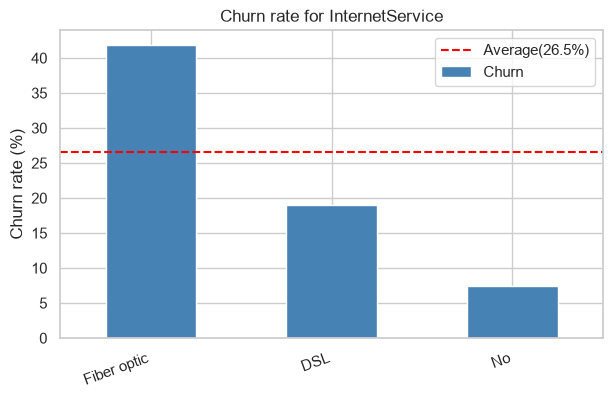

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64

In [7]:
plot_churn_rate("InternetService")

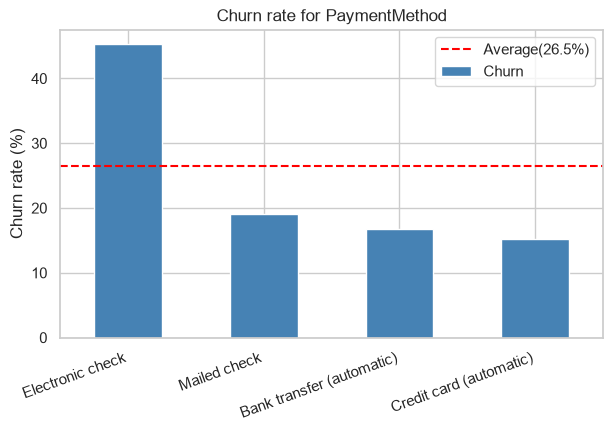

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64

In [8]:
plot_churn_rate("PaymentMethod")

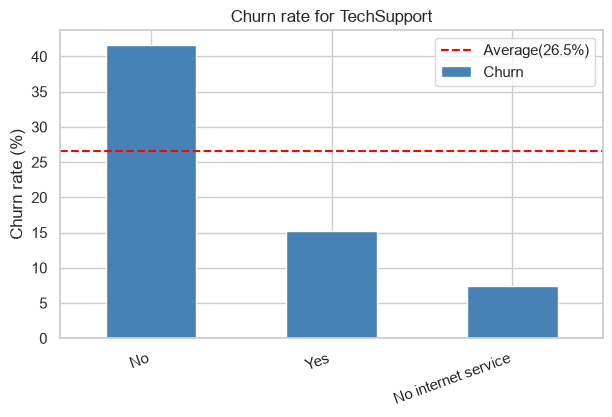

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64

In [9]:
plot_churn_rate("TechSupport")

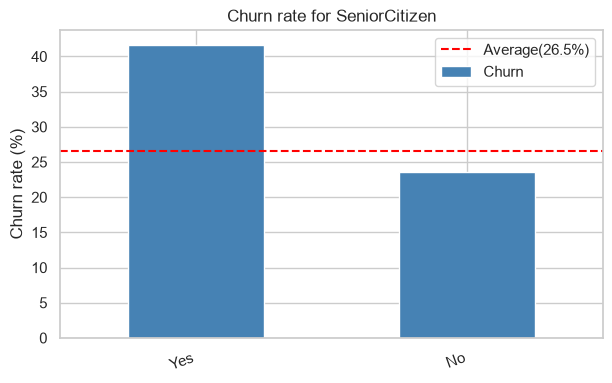

SeniorCitizen
Yes    41.7
No     23.6
Name: Churn, dtype: float64

In [10]:
plot_churn_rate("SeniorCitizen")

## Findings: who churns?

- **Contract:** month-to-month customers churn at 42.7%, vs 2.8% on two-year contracts.
  → Offer discounts to move customers to longer contracts.
- **Internet:** fiber optic users churn the most (41.9%), even though it's the premium service.
  → Possible price or quality problem with fiber. Worth investigating.
- **Payment:** electronic check users churn at 45.3%, vs ~15-17% for automatic payments.
  → Encourage automatic payment (e.g. a small discount for switching).
- **Tech support:** customers without tech support churn at 41.6% vs 15.2% with it.
  → Offer free tech support trials to at-risk customers.
- **Seniors** churn more (41.7% vs 23.6%).

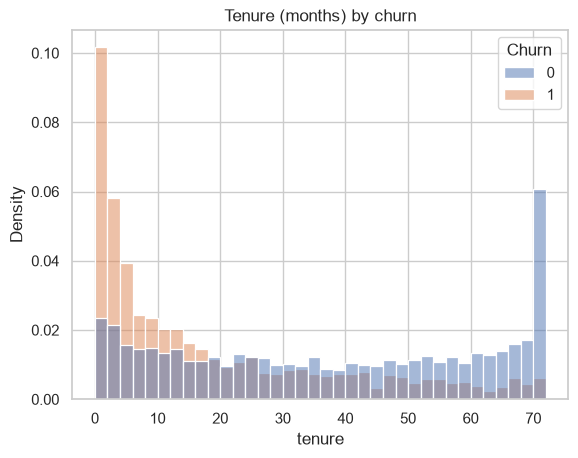

In [11]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=36,
             stat="density", common_norm=False)
plt.title("Tenure (months) by churn")
plt.savefig("../images/tenure_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

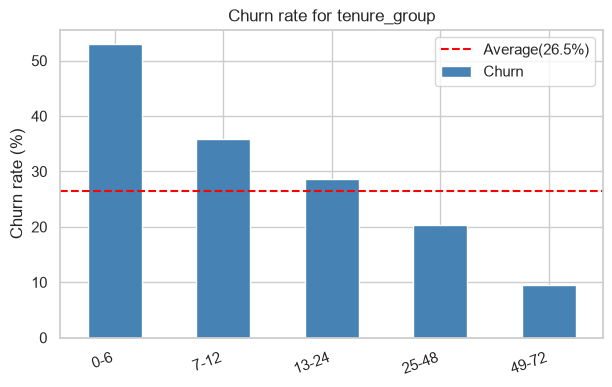

tenure_group
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn, dtype: float64

In [12]:
df["tenure_group"] = pd.cut(df["tenure"],
                            bins=[-1, 6, 12, 24, 48, 72],
                            labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
plot_churn_rate("tenure_group")

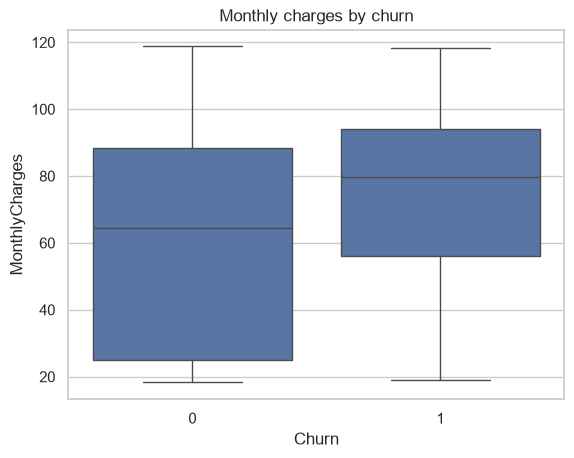

Churn
0    64.425
1    79.650
Name: MonthlyCharges, dtype: float64

In [13]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges by churn")
plt.savefig("../images/charges_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("Churn")["MonthlyCharges"].median()

In [14]:
lost_monthly = df.loc[df["Churn"] == 1, "MonthlyCharges"].sum()
total_monthly = df["MonthlyCharges"].sum()

print(f"Monthly revenue lost to churn: ${lost_monthly:,.0f}")
print(f"Share of total revenue:        {lost_monthly / total_monthly:.1%}")
print(f"Per year:                      ${lost_monthly * 12:,.0f}")

Monthly revenue lost to churn: $139,131
Share of total revenue:        30.5%
Per year:                      $1,669,570


## Findings: tenure, charges and revenue

- **New customers are the biggest risk:** 52.9% churn in their first 6 months,
  vs only 9.5% after 4 years. → Focus retention efforts on the first 6 months
  (onboarding calls, welcome discounts).
- **Churners pay more:** median $79.65/month vs $64.43 for customers who stay.
- **Cost of churn:** churned customers represented **$139K per month (~$1.67M per year)**,
  which is **30.5% of revenue**, more than their 26.5% share of customers.
  The company is losing its higher-value customers.

## Summary: profile of a high-risk customer
New (under 6 months), month-to-month contract, fiber optic internet,
pays by electronic check, no tech support.